# AI 활용에 관하여

과제는 AI 를 사용할 것을 전제로 만들어지고 있습니다.
하지만, 학습의 효율성을 위해서 무분별한 AI 사용은 권장드리지 않고 있어요.

따라서, AI 를 피어리뷰어로서 생각하고 사용해주시는 것을 권고드립니다.  
이를 판단할 수 있는 하나의 기준으로는 같은 수업을 듣는 다른 친구에게 물어볼 수 있는 질문인가? 라고 스스로 물어보는 것도 좋은 기준이 될 수 있을 것 같습니다.

아래는 이에 대한 몇가지 예시입니다.


> AI 사용 가능:
> - 문법 및 API 확인
> - 오류 메시지 해석
> - 실행 환경 문제 해결
> - 내가 작성한 설명의 반례 요청

> AI에 맡기지 않을 것:
> - 실행 전 예측
> - 실행 결과에서 근거 선택
> - 의견 및 선택의 최종 판단


# 4주차 과제: CNN 활용과 전이학습

3주차에는 이미지의 공간 구조와 convolution을 살펴보았습니다. 이번에는 skip connection을
가진 블록을 만들고, 이미 학습된 모델의 입력과 출력 양쪽에 새 구조를 붙여봅시다.

이번에도 실행 전 예상과 실행 후 해석을 나누어 작성해주세요.
먼저 아래 설정 셀을 실행해주세요.


## 목차

1. [스터디 내용 복습하기](#review)
2. [두 Residual Block 만들기](#blocks)
3. [Batch Normalization](#batch-normalization)
4. [기존 ResNet 코드 살펴보기](#read-code)
5. [새 Task: 흑백 이미지에서 개/고양이 분류하기](#subtask)
6. [Checkpoint 복원과 최종 평가](#restore)
7. [마무리](#wrap-up)
8. [선택 심화: Representation Learning](#extra)


In [6]:
from pathlib import Path
import sys

WEEK4 = Path.cwd()
if not (WEEK4 / "resnet" / "resnet-classroom").is_dir():
    WEEK4 = WEEK4 / "week4"
if not (WEEK4 / "resnet" / "resnet-classroom").is_dir():
    raise RuntimeError("저장소 루트 또는 week4 폴더에서 노트북을 열어주세요.")
sys.path.insert(0, str(WEEK4.resolve()))

from support.runtime import (
    keras, np, tf, TASK_DATA, RUNS,
    load_frozen_encoder, make_empty_encoder,
    read_source_manifest, write_species_manifest, read_species_data,
    show_data_summary, create_run, write_json, show_predictions,
)
from support.checks import (
    check_basic_block, check_bottleneck_block,
    check_species_labels, check_grayscale, check_dataset, check_task_model,
)
from support.benchmark import compare_blocks
from support.checkpoints import EpochCheckpoints, read_checkpoints, check_restored_predictions

keras.utils.set_random_seed(42)
print("TensorFlow:", tf.__version__)
print("week4:", WEEK4.resolve())
print("기존 A 가중치를 사용하므로 ImageNet 다운로드는 필요 없습니다.")


TensorFlow: 2.21.0
week4: C:\Users\USER\project\deep-learning-study\week4
기존 A 가중치를 사용하므로 ImageNet 다운로드는 필요 없습니다.


<a id="review"></a>
# 1. 스터디 내용 복습하기

**Q1-0.** AI 개발자들은 Layer 가 더 깊어지면, 그 성능이 더 높아질 것이라고 기대했습니다.  
이는 무엇에 근거한 주장이었나요?  
(이론적인 내용이라 조금 어렵습니다. LLM 을 열심히 괴롭혀봅시다.)

참고자료:
* 키워드: universal approximation theorem
* 강의 형식을 원하신다면:
  * 강의: https://ocw.mit.edu/courses/6-7960-deep-learning-fall-2024/resources/mit6_7960f24_lec03_mp4/
  * 강의록: https://ocw.mit.edu/courses/6-7960-deep-learning-fall-2024/resources/mit6_7960_f24_lec3_pdf/

**신경망의 Layer가 깊어질수록 더 복잡한 함수를 효율적으로 표현할 수 있기 때문이다. 이러한 기대는 보편 근사 정리(Universal Approximation Theorem)와 깊이 분리(Depth Separation)에 이론적 근거를 둔다.
1. 보편 근사 정리
보편 근사 정리에 따르면 적절한 활성화 함수를 사용하는 신경망은 충분한 수의 뉴런을 가질 경우 일정한 조건을 만족하는 함수를 원하는 정확도에 가깝게 근사할 수 있다.
이는 신경망이 복잡한 함수를 표현할 수 있는 능력을 가지고 있다는 의미다.
하지만 보편 근사 정리가 깊은 신경망의 필요성을 직접적으로 증명하는 것은 아니다. 얕은 신경망도 충분히 넓다면 복잡한 함수를 근사할 수 있기 때문이다.
2. 깊이 분리(Depth Separation)
그렇다면 신경망의 깊이를 늘리는 이유는 같은 함수를 표현하는 데 필요한 뉴런의 수다.
깊은 신경망이 비교적 적은 수의 뉴런으로 표현할 수 있는 함수를, 얕은 신경망에서는 지수적으로 많은 뉴런을 사용해야 표현할 수 있는 사례를 소개한다.
예를 들어 ReLU 신경망은 구간별 선형 함수(Piecewise Linear Function)를 표현한다. 여러 층을 거치며 함수를 합성하면 선형 구간의 수가 크게 증가할 수 있다.
단순히 뉴런을 많이 사용하는 것보다 여러 층을 통해 함수를 단계적으로 합성하는 편이 특정한 복잡한 함수를 표현하는 데 효율적일 수 있다.**

**Q1-1.** ResNet 이 풀고자 한 문제는 Layer 가 더 깊어짐에도 불구하고, 성능이 하락하는 Degradation Problem 이었습니다.  
구체적으로 어떤 문제였는지 더 자세히 풀어주세요.  
그리고, ResNet 은 이 문제를 어떤 관점으로 해결했나요? 이 관점을 구체화한 것이 어떤 구조인가요?

**Degradation Problem은 Layer가 깊어질수록 오히려 학습 오차가 증가하는 현상이다. 이론적으로 추가된 Layer가 입력을 그대로 전달하는 항등함수를 학습하면 기존 모델의 성능을 유지할 수 있지만, 실제로는 이를 최적화하기 어려웠다.
ResNet은 이를 해결하기 위해 Residual Learning(잔차 학습)을 도입했다. 목표 함수 (H(x))를 직접 학습하는 대신, 입력과 출력의 차이인 (F(x)=H(x)-x)를 학습하는 방식이다.
이를 구현한 Skip Connection은 입력 (x)를 출력에 직접 더하여 (H(x)=F(x)+x)를 구성한다. 이 구조는 항등함수 학습을 쉽게 만들고 역전파 과정에서 기울기 전달을 도와 깊은 신경망의 최적화 문제를 완화한다.**

**Q1-Extra.** ResNet 의 관점(Q1-1) 과 비슷한 개념이 자연어처리에도 있습니다.  
가볍게 내용을 조사해봅시다.  
**Warning: 자연어처리에서 사용되는 Attention 알고리즘, Transformer 구조에 대한 기본적인 이해가 필요합니다.** 
**잘 모르겠다면 넘어갑시다.**

참고자료:
* 원문: https://transformer-circuits.pub/2021/framework/index.html
* 번역 & 요약본: https://hibyeys.tistory.com/13
* Transformer 가 궁금하다면
  * https://youtu.be/wjZofJX0v4M?si=VC6hyxBnsLEDURsN
  * https://youtu.be/eMlx5fFNoYc?si=LXeDavy5DEX7V4M1


**ResNet의 Skip Connection과 유사한 구조로 Transformer의 Residual Connection(잔차 연결)이 있다.
Transformer에서는 Attention과 MLP가 입력 정보를 변환한 뒤, 그 결과를 기존 입력에 더하는 방식을 사용한다.
이는 ResNet과 마찬가지로 기존 정보를 유지하면서 새로운 정보를 추가하고 역전파 시 기울기 전달을 도와 깊은 신경망의 학습을 용이하게 한다.
특히 Transformer에서는 이러한 정보가 누적되는 경로를 Residual Stream이라고 부른다. 각 Layer는 이 경로에서 정보를 읽고 처리한 결과를 다시 더한다.
즉 ResNet과 Transformer 모두 입력을 완전히 새로운 값으로 대체하기보다 기존 정보에 변화를 누적하는 구조를 활용한다는 공통점이 있다**

**Q2.** 다음의 질문을 정리해봅시다.  
답변을 작성할 때, 되도록이면 다른 자료(인터넷, LLM 등) 을 참고하지 않고, 머리에서 생각나는대로 먼저 정리해봅시다.  
**이 과정을 통해서 여러분만의 프레임을 만들어가게 됩니다. 꼭 다른 자료 참고하지 말고 적어보세요!!!**  
다 적은 다음에 외부 자료를 활용하여 보강해주세요.

- Transfer Learning
  - Transfer Learning 이 해결하고자 하는 문제가 무엇인가요?
  - 어떤 관점으로 해결했나요?
  - Inductive Bias 와는 어떤 차이가 있나요?
    - 구체적으로, 관점이 어떻게 다르고, 그 관점을 어떻게 실행하나요?

- Fine Tuning, Data Augmentation, Distillation
    - Fine Tuning 은 Model 을 어떻게 분해하고 재구성하나요? "Block 단위" 라는 것이 어떤 의미인가요?
    - 재구성의 구체적인 방법이 무엇인가요?
    
    - Data Augmentation 은 데이터를 늘려서 Model 학습에 사용하는 방법입니다. 어떻게 데이터를 늘리나요?
    - 크게 2가지 방식이 존재했는데, 2가지 방식을 비교해주세요. 그 2개가 완전 다른 방식인가요?
    
    - Distillation 과 Data Augmentation 은 어떻게 다른가요? 정답 Label 에 집중해서 비교해주세요.
    - 이번에는 Pretrained Model 의 접근성으로 비교해주세요.  
    예를 들어, ChatGPT 로 Distillation 과 Data Augmentation 이 모두 가능할까요?

**모델을 처음부처 학습시키는데에는 많은 자원이 들어가기 떄문에 이미 학습한 모델을 새로운 모델에 활용하는 방법을 제시하였다. inductive bias의 경우 구조에 어떠한 가정을 반영하고 표현력을 제한하여 해당 도메인에서 더 효율적인 학습을 가능하게 한다. Transfer Learning은 이전에 학습한 지식을 활용한다는 차이가 있다.  Block은 모델 내부의 여러 Layer를 하나의 기능적 단위로 묶은 것이다. 새로운 문제를 해결하려면 특정한 블록을 유지하고 다른 블록은 문제에 적합한 방식으로 재구성할 수 있다. Data Augmentation은 데이터가 부족할때 다양성을 늘리는 방법이다. 기존 이미지의 회전, 밝기, 채도 등을 변경하는 방법과 생성형 AI로 새로운 이미지를 생성하는 방법등이 있다. Distillation은	기존 모델의 예측을 활용하는 방식으로 정답 외에 예측 확률도 활용한다.   Data Augmentation 기존 또는 생성된 데이터의 정답 Label을 유지하거나 함께 변형하는 방식이다. ChatGPT 의 경우  Data Augmentation에는 활용할 수 있지만 모델의 예측치가 공개되있지 않은 이상 Distillation에 활용하는 것은 어려울것 같다.**

<a id="blocks"></a>
# 2. 두 Residual Block 만들기

Bottleneck 은 residual block 과 유사하지만, 연산량을 줄이는 것을 목표로 합니다.  
이번에는 **Basic Residual Block**과 **Bottleneck Residual Block**을 같은 입력과 출력 크기로 만들어보고, 비교해봅시다.

3주차에는 `Sequential`로 층을 쌓았습니다.  
이번에는 중간 경로를 더하기 위해 Functional API를 사용합니다. 아래는 문법을 확인하는 작은 예시입니다.

In [7]:
example_input = keras.Input(shape=(4,))
branch = keras.layers.Dense(4)(example_input)
example_output = keras.layers.Add()([branch, example_input])
example_model = keras.Model(example_input, example_output)
print("입력:", example_model.input_shape, "출력:", example_model.output_shape)
keras.utils.plot_model(
    example_model,
    show_shape=True
)

입력: (None, 4) 출력: (None, 4)
You must install pydot (`pip install pydot`) for `plot_model` to work.


`Sequential` 은 단어 의미 그대로, Layer 를 순차적으로 쌓을 수 있습니다.  
하지만, 이번에 만들 Residual Block 은 순차적으로 쌓지 않습니다.  
러프하게는 "입력을 가공한 것" + "입력" 의 형태이기 때문에 이전의 상태가 필요합니다.  
Functional API 는 Layer 간의 다양한 연산을 지원하기 때문에 다양한 구조에 대응할 수 있습니다.  
구체적으로는 DAG(Directed Acyclic Graph) 구조라면 가능합니다.  

자세한 내용은 다음의 자료를 참고해보세요.
* https://keras.io/guides/functional_api/
* https://wikidocs.net/38861

## Q3. Basic Block 구현하기

아래 순서대로 층을 연결하고 Keras Model을 반환해주세요.

```text
F(x): x -> Conv3x3(output channel: 64) -> BN -> ReLU -> Conv3x3(output channel: 64) -> BN
```

$$
y = \operatorname{ReLU}(x + F(x))
$$

- 입력과 출력 한 장의 shape: `(16, 16, 64)`
- 모든 Conv: stride 1, `padding="same"`, `use_bias=False`, Conv 자체의 activation은 기본값
- BN은 `keras.layers.BatchNormalization()`의 기본값 사용
- ReLU는 별도 `keras.layers.ReLU()`로 배치
- 마지막 Conv 뒤에는 바로 ReLU를 두지 않고 shortcut과 더한 다음 적용

**HINT: 기존의 `Sequential` 에서 사용한 `Layer` 를 그대로 사용하지만, Funtional API 로 표현될 뿐입니다.**  
**HINT2: 이번에는 `x` 와 `F(x)` 를 더해야하는데, 이 연산은 element-wise Operation 을 하는 어떤 `Layer` 로 처리할 수 있습니다.**

**둘 다 Skip Connection을 통해 잔차를 학습한다는 점은 동일하다. Basic Block은 3×3 Convolution을 두 번 사용하고 Bottleneck Block은 1×1 Convolution으로 채널을 압축한 뒤 중간에 연산량이 큰 3×3 Convolution 적은 채널로 수행해 연산량을 줄이는 구조다**


In [8]:
def build_basic_block():
    inputs = keras.Input(shape=(16, 16, 64))
    

    # TODO 1: Conv -> BN -> ReLU
    x = keras.layers.Conv2D(
        64, (3, 3), strides=1, padding="same", use_bias=False
    )(inputs)
    x = keras.layers.BatchNormalization()(x)
    x = keras.layers.ReLU()(x)

    # TODO 2: Conv -> BN
    x = keras.layers.Conv2D(
        64, (3, 3), strides=1, padding="same", use_bias=False
    )(x)
    x = keras.layers.BatchNormalization()(x)

    # TODO 3: Skip Connection -> ReLU
    x = keras.layers.Add()([inputs, x])
    outputs = keras.layers.ReLU()(x)

    return keras.Model(inputs=inputs, outputs=outputs)
    


### 채점머신 - Q3
함수를 완성한 뒤 실행해주세요.  
구성과 출력 shape를 확인하고, residual 경로를 0으로 만들었을 때 shortcut이 남아 있는지도 확인합니다.  

In [9]:
check_basic_block(build_basic_block)

🎉 블록 채점 통과: shape, 구성, 파라미터 수, shortcut을 확인했습니다.


## Q4. Bottleneck Block 구현하기

이번에는 비싼 $3 \times 3$ 연산 전에 채널을 줄이고, 마지막에 다시 복원합니다.

```text
F(x): x -> Conv1x1(16) -> BN -> ReLU -> Conv3x3(16) -> BN -> ReLU -> Conv1x1(64) -> BN
```

$$
y = \operatorname{ReLU}(x + F(x))
$$

입출력 shape와 Conv, BN, ReLU의 공통 조건은 Q3과 같습니다.  
**이번에는 `conv` 연산의 결과로 Channel 이 달라짐을 유의해주세요!**  

**Q-Extra:** Skip Connection 은 Block 의 입력과 출력의 결과물을 합치는 과정이 존재합니다.  
만약 입력과 출력의 Shape 가 다르면 어떻게 될까요?  
예를 들어, 입력은 (16, 16, 64) 이지만 F(x) 의 결과가 (32, 32, 32) 라면, 어떻게 될까요?

In [10]:
def build_bottleneck_block():
    inputs = keras.Input(shape=(16, 16, 64))

    # TODO 1: 1x1 Conv(16) -> BN -> ReLU
    x = keras.layers.Conv2D(
        16, (1, 1), strides=1, padding="same", use_bias=False
    )(inputs)
    x = keras.layers.BatchNormalization()(x)
    x = keras.layers.ReLU()(x)

    # TODO 2: 3x3 Conv(16) -> BN -> ReLU
    x = keras.layers.Conv2D(
        16, (3, 3), strides=1, padding="same", use_bias=False
    )(x)
    x = keras.layers.BatchNormalization()(x)
    x = keras.layers.ReLU()(x)

    # TODO 3: 1x1 Conv(64) -> BN
    x = keras.layers.Conv2D(
        64, (1, 1), strides=1, padding="same", use_bias=False
    )(x)
    x = keras.layers.BatchNormalization()(x)

    # TODO 4: Skip Connection -> ReLU
    x = keras.layers.Add()([inputs, x])
    outputs = keras.layers.ReLU()(x)

    return keras.Model(inputs=inputs, outputs=outputs)

In [11]:
check_bottleneck_block(build_bottleneck_block)

🎉 블록 채점 통과: shape, 구성, 파라미터 수, shortcut을 확인했습니다.


## Q5. 파라미터 수와 실행 시간 비교하기

실행 전에 어느 블록의 파라미터가 적고, 어느 블록이 더 빠를지 이유와 함께 예상해주세요.  
측정 후에는 예상과 다른 부분을 2~3문장으로 정리합니다.

제공된 함수는 다음 세 가지만 출력합니다.

1. `count_params()`의 총 파라미터 수: BN의 비학습 파라미터를 포함합니다
2. 같은 batch를 추론하는 실제 시간의 중앙값(ms 단위)
3. Conv MAC(Multiply-Accumulate): 이미지 한 장의 Conv 곱셈 시에 행해지는 곱셈 후 더하기 연산의 횟수

시간은 CPU, float32, batch 8로 맞추고, 측정 전에 10회 실행 후, 30회 측정합니다.  
준비 과정은 제외하고, 계산에 대한 시간만 측정합니다. 장비, 실행 환경에 따라 결과가 달라집니다.

**TMI: MAC 연산은 여러 하드웨어에서 지원하기 때문에, "곱하고 더하기" 라는 2번의 연산을 한번에 처리합니다.**  
참고자료: https://en.wikipedia.org/wiki/Multiply%E2%80%93accumulate_operation

비슷한 단어로는 **"FLOPs"** 라는 단어가 있습니다. 이 단어는 하드웨어의 성능을 나타내는 지표의 단위로서 종종 사용되곤 합니다.

**bottelneck의 경우가 3x3 연산을 더 적은 수의 채널로 진행하기 때문에 파라미터의 수는 더적고 속도가 더 빠를것이다.**


In [12]:
with tf.device("/CPU:0"):
    basic_block = build_basic_block()
    bottleneck_block = build_bottleneck_block()

benchmark_results = compare_blocks({
    "Basic": basic_block,
    "Bottleneck": bottleneck_block,
})


CPU / float32 / batch=8 / warmup=10 / repeats=30
파라미터 수는 BN의 비학습 통계도 포함합니다. 시간은 같은 환경 안에서 비교하세요.
block            parameters     batch ms    Conv MACs/image
Basic                74,240        4.007         18,874,368
Bottleneck            4,736        1.060          1,114,112


**결과 해석**
- 파라미터 수와 실행 시간은 같은 비율로 줄었나요?
- 중간 채널을 줄여도 출력 shape가 같다는 사실만으로 표현 능력이나 정확도도 같다고 할 수 있을까요?

Residual Block 도, Bottleneck Block 도 입력과 출력의 Shape 는 동일합니다.  
하지만, 내부 연산에서의 Shape 는 달라집니다.  

Bottleneck 은 연산량을 줄이기 위해, Channel 을 낮춘 채로 연산 후, 다시 Channel 을 늘리는 과정을 거칩니다.  
이 과정이 기존의 Channel 을 그대로 사용하는 Residual 과 어떻게 다를까요?  

정답이 있는 질문은 아니니, 자유롭게 적어봅시다.

**예상과 같이 Bottleneck의 파라미터 수와 실행 시간이 모두 감소했지만 감소 비율에는 차이가 있었다. 파라미터 수와 MACs는 약 94% 감소한 반면 실행 시간은 약 62% 감소했다. 이는 실행 시간이 단순한 연산량뿐 아니라 Layer 호출과정에서 영향을 받기 때문으로 생각된다. 또한 두 Block의 출력 Shape가 같더라도 표현력이나 정확도가 동일하다고 볼 수는 없다. Bottleneck은 중간 채널 수를 줄여 연산 효율을 높이는 대신, 정보 표현에 제약이 생길 수 있다. 따라서 두 구조의 실제 성능 차이를 확인하려면 동일한 데이터셋에서 학습한 뒤 정확도를 비교해야 한다.**

<a id="batch-normalization"></a>
# Batch Normalization

BN은 정규화처럼, 데이터의 특성을 일정 평균과 분산을 이루도록 변형해줍니다.  
단, 정규화와는 다르게 평균 0, 분산 1 을 만족하지 않을 수도 있습니다.
이 연산은 보통 최적화를 더 안정적이고 빠르게 하는 데 도움된다고 알려져 있습니다.

평균과 분산을 바꾸는 변수는 보통 Beta, Gamma 로 표현되고, 이는 Layer 가 내부적으로 연산하게 되어있습니다.  
Keras 의 파라미터에서 이를 조절하는 방식을 정할 수 있습니다.

이 연산이 왜 최적화를 도와줄까요?  

이를 위해서 입력 데이터에 대해서 데이터 전처리로서 정규화를 진행했다고 가정해봅시다.  

<img src="./imgs/normalization-contours.gif" width=600>

정규화되지 않으면, 방향이 지속적으로 수정되어야하기 때문에 효율적으로 이동할 수 없습니다.

이는 입력데이터에 대한 이야기였지만, 이번엔 연산 중간 즉, Layer 간 사이의 중간 결과라고 생각해봅시다.  
Layer 입장에서는 입력데이터일 뿐, 그 데이터가 어떤 변환을 거쳤는지 모르기 때문에 같은 원리를 적용해볼 수 있습니다.  

지금까지의 설명에 참고한 자료를 첨부합니다.  
한가지 첨언하자면, BN 가 효과적임은 경험적으로 알려져있으나, 이에 대한 이론적인 답은 아직 명확하지 않습니다.  
이런 견해와 해석도 있구나 정도로 봐주시면 좋을 듯합니다.

* [Batch Norm Explained Visually - Why does it work](https://towardsdatascience.com/batch-norm-explained-visually-why-does-it-work-90b98bcc58a0/)
* [Batch Norm Explained Visually - How it works, and why neural networks need it](https://towardsdatascience.com/batch-norm-explained-visually-how-it-works-and-why-neural-networks-need-it-b18919692739/)
  * 구체적인 실행 과정이 적혀있습니다. 학습/추론이냐에 따라 어떻게 연산되는지, Learnable 변수에 대해 살펴보면 좋을듯합니다.

이번 구현에서는 직접 구현하지 않고, Keras 의 BN 을 사용합니다.

<a id="read-code"></a>
# 기존 ResNet 코드 살펴보기

아래는 별도 장문의 비교 과제가 아닌 **새 Task 구현을 위한 읽기 안내**입니다.
LLM에 A~E 코드를 살펴보고 다양하게 질문하면서 구체적으로 어떻게 작성되었는지 살펴봅시다. 
실제 파일을 열어 설명이 맞는지 확인해보세요.

아래는 예시 프롬프트입니다.

> A~E를 데이터 읽기 -> 초기 가중치 -> 학습할 층 -> 입력과 출력 shape -> loss -> 저장 -> 추론 순서로
> 설명해줘. 설명마다 파일명과 함수 또는 관련 코드를 근거로 붙여줘.
> 원본 이미지의 입력과 head가 받는 중간 특징의 입력을 구분해줘.

시작 파일은 아래와 같습니다.
* [A 학습](resnet/resnet-classroom/a_base/train.py)
* [B 학습](resnet/resnet-classroom/b_domain/train.py)
* [C 학습](resnet/resnet-classroom/c_augmentation/train.py)
* [D 학습](resnet/resnet-classroom/d_dog_breeds/train.py)
* [E 모델](resnet/resnet-classroom/e_localization/model.py)

전체 개요는 [Python 실습 안내](resnet/resnet-classroom/README.md)를 참고해주세요.
그 외로도 안내 문서와 주석이 적혀있으니 확인해보세요.

확인할 지점:
- 각 모델은 어떤 모델의 가중치를 어디까지 재활용하나요?
  - 일부 Layer 는 가져오고 추가학습하는 경우도, 아예 새로운 Layer 를 붙이는 경우도 있습니다.
- 일부 Layer 를 가져온 경우, 일반적으로 왜 작은 learning rate 를 사용할까요?
  - BN 에 대해서도, 고정된 학습 파라미터와 기존 통계량(moving average, variance) 를 유지합니다. 왜 그럴까요?
- 각 모델별로 문제와 입력과 출력이 조금씩 다릅니다. 어떻게 다른지, 동일한 참고 모델임에도 불구하고 다른 문제를 풀 수 있는 이유가 뭘까요?

LLM의 답변은 처음에 흐름을 잡고, 검토하는 용도로 사용합니다. 코드를 근거로 확인한 부분만 자신의 설명에 채택해주세요.

### 코드를 이해할 때 참고해볼만한 기술적인 HINT (`Model` vs `Layer`)

```python
# resnet-classroom/b-domain/train.py main 의 일부
model, _, backbone, head = load_base()
    backbone.trainable = True
    for layer in backbone.layers:
        layer.trainable = (layer.name.startswith(("conv4_", "conv5_"))
                           and isinstance(layer, keras.layers.Conv2D))
    head.trainable = True
```
위 코드는 기본 모델을 불러오고, 기본 모델의 일부만을 새로운 데이터를 통해 학습가능하게 설정해주는 코드입니다.(`Trainable`)  
이 때 `backbone` 은 `ResNet50` 의 일부이며, `head` 는 분류를 위한 Dense Layer 의 모음입니다.  

여기서 `backbone` 의 일부(conv4, 5 에서의 conv2D 연산) 만을 추가학습시키기 위해, `Trainable = True` 로 설정해주고 있습니다.  
이를 위해서는 먼저 `model` 이 `Trainable` 하다고 설정해주고, `model` 의 `layer` 에 대해 개별적으로 `Trainable` 을 설정해주는 것입니다.  

모델인 `model` 과 `model.layers` 가 둘다 동일한 방식으로 설정되는 이유는,  
`model` 은 `layer` 를 상속(객체지향) 하고 있기 때문입니다.  

```shell
Layer
  Conv2D
  BatchNormalization
  Model
    Functional    # ResNet50의 실제 타입
    Sequential
```

Model 의 `Trainable` 이 먼저 설정되어야하는 이유는,  
예를 들어 `not_trainable_model` 가 `Trainable=False` 이지만, 내부 `Layer` 의 첫번째 `Dense` 가 `Trainable=True` 라고 해봅시다.  

```python
# keras/src/layers/layer.py line 733
@property
def trainable_weights(self):
    if not self.trainable:
        return []
    return [v for v in self.weights if v.trainable]
```

위 코드처럼, `model`, `layer` 모두 자기자신이 `Trainable` 한지 확인한 다음, `Trainable 한 가중치를 가져옵니다.  
`not_trainable_model` 의 경우, 이 값이 `False` 이기 때문에 하위 Layer 를 확인하지 않고, 빈 리스트를 반환하게 됩니다.

정리해본다면 다음과 같이 행동하게 됩니다.  
> 자기자신이 학습가능한지 확인한 다음, 자신이 가지고 있는 하위 Layer 가 학습가능한지 확인한다.

따라서, 학습 범위를 설정할 때는 Bottom-Up, 즉 해당 Layer 를 직접 확인하는 것이 아닌,  
Top-Down, 즉 전체 모델에서 무엇을 학습하는지 내려오는 것이 중요합니다.

<a id="subtask"></a>
# 3. 새 Task: 흑백 이미지에서 개/고양이 분류하기

기존 A는 6품종 RGB 분류 모델입니다. 이번에는 **흑백 한 채널을 입력받아 cat/dog를 구분**하도록
입력과 출력 양쪽에 새 구조를 붙여봅시다.

```text
RGB 원본 -> 흑백(160x160x1)
         -> 학습 가능한 입력 adapter(1->3채널)
         -> 고정 encoder(기존 전처리 + ResNet + GAP)
         -> 새 head(Dense64 -> Dense2) -> cat/dog logits
```

기본 원본 540장의 분할(train 360 / validation 90 / test 90)을 유지하고 새 label을 만듭니다.  
이미지는 복사하지 않고 기존 파일을 참조하며, 이번 Task 에서는 입출력 Layer 만을 새롭게 정의하고, 학습합니다.

## Q6. 새 label 만들기

원래 품종 ID는 다음과 같습니다.

| ID | 품종 | 새 종 label |
|---:|---|---:|
| 0 | Birman | cat = 0 |
| 1 | Ragdoll | cat = 0 |
| 2 | Siamese | cat = 0 |
| 3 | Beagle | dog = 1 |
| 4 | Pug | dog = 1 |
| 5 | Shiba Inu | dog = 1 |

`species_labels`는 품종 ID의 1차원 정수 배열을 받아 같은 길이의 종 label 정수 배열을 반환합니다.  
원본 배열은 변경하지 않습니다. `np.where`, 비교 연산 등을 사용할 수 있습니다.

In [13]:
def species_labels(breed_ids):
    return np.where(breed_ids <= 2, 0, 1)

In [14]:
check_species_labels(species_labels)

종 label 채점 통과


아래 제공 코드는 새 label을 원본 이미지와 split을 연결해 `subtask/data/manifest.csv`에 저장합니다.  
`path`는 CSV 위치 기준의 상대 경로이고, `classes.json`의 배열 순서가 label ID입니다.  

```json
// classes.json
[
  "cat", // label ID = 0
  "dog" // label ID = 1
]
```
예를 들어 Ragdoll(ID = 2) 은 고양이 품종이므로, label ID = 0 으로 저장됩니다.

In [15]:
source_rows = read_source_manifest()
breed_ids = np.array([int(row["breed_id"]) for row in source_rows])
manifest = write_species_manifest(source_rows, species_labels(breed_ids))
rgb_images, labels, splits, rows = read_species_data(manifest)
show_data_summary(labels, splits)
check_dataset(rows, labels, splits)
print("저장한 목록:", manifest)

split       cat  dog  total
train       180  180   360
validation   45   45    90
test         45   45    90
데이터 확인 통과: 원본 split, 종 label, 클래스별 개수가 맞습니다.
저장한 목록: C:\Users\USER\project\deep-learning-study\week4\subtask\data\manifest.csv


## Q7. 흑백 입력 준비하기

`to_grayscale`은 RGB 이미지 묶음을 받아 `(N, H, W, 1)` 형태의 NumPy 배열을 반환합니다.  
`tf.cast(..., tf.float32)`로 바꾼 뒤 `tf.image.rgb_to_grayscale`을 사용해주세요.  
값의 범위는 0~255로 유지하며 `/255` 의 정규화는 추가하지 않습니다. ResNet 관련 전처리는 encoder 안에 있습니다.

In [16]:
def to_grayscale(rgb_images):
    # float32 변환
    images = tf.cast(rgb_images, tf.float32)

    # RGB -> Grayscale
    gray_images = tf.image.rgb_to_grayscale(images)

    # NumPy 배열 반환
    return gray_images.numpy()

In [17]:
check_grayscale(to_grayscale)
gray_images = to_grayscale(rgb_images)
print("RGB:", rgb_images.shape, "-> 흑백:", gray_images.shape)
train = splits == "train"
validation = splits == "validation"

흑백 변환 채점 통과
RGB: (540, 160, 160, 3) -> 흑백: (540, 160, 160, 1)


## Q8. 입력 adapter와 새 head 연결하기

`build_task_model(encoder)`를 완성해주세요.

- 입력: `(160, 160, 1)`
- 입력 adapter: `Conv2D(3, 1, kernel_initializer="ones", bias_initializer="zeros", name="input_adapter")`
- 제공 encoder는 `trainable=False`, 호출할 때도 `training=False`로 연결합니다.
- head: `Dense(64, activation="relu") -> Dense(2)`
- 마지막 출력은 softmax를 적용하지 않은 logits 을 그대로 반환합니다.

전체 흐름은 다음과 같습니다.
```text
흑백 이미지(160, 160, 1) -> adapter(Conv2D) -> encoder(ResNet 전처리, backbone, GAP) -> head(Dense(64), Dense(2)) -> cat/dog logit
```

In [18]:
def build_task_model(encoder):
    encoder.trainable = False
    inputs = keras.Input(shape=(160, 160, 1))

    # TODO 1: 흑백 1채널 -> RGB 3채널
    x = keras.layers.Conv2D(
        3, 1,
        kernel_initializer="ones",
        bias_initializer="zeros",
        name="input_adapter"
    )(inputs)

    # TODO 2: 고정된 encoder 연결
    x = encoder(x, training=False)

    # TODO 3: 새로운 분류 Head
    x = keras.layers.Dense(64, activation="relu")(x)
    outputs = keras.layers.Dense(2)(x)

    # TODO 4: 모델 반환
    return keras.Model(inputs=inputs, outputs=outputs)

In [19]:
keras.utils.set_random_seed(42)
encoder = load_frozen_encoder()
task_model = build_task_model(encoder)
check_task_model(task_model, encoder)
print("출력:", task_model.output_shape)
print("학습 파라미터:", sum(int(np.prod(w.shape)) for w in task_model.trainable_weights))

🎉 모델 확인 통과: adapter, head 학습 / encoder 고정 / gradient 연결
출력: (None, 2)
학습 파라미터: 131272


## Q9. 학습 & checkpoint 보관하기

아래 설정으로 시작합니다.  
실행 전에 validation 정확도와 loss가 어떻게 변할지 예상해주세요.
정확도 목표치를 맞추거나 test를 보면서 설정을 반복 조정할 필요는 없습니다.

- Adam learning rate `1e-3`, batch `8`, epoch `3`, seed `42`
- loss는 `SparseCategoricalCrossentropy(from_logits=True)`
- metric 이름은 `accuracy`
- `fit()`의 입력은 흑백 **train** 이미지

제공 코드는 실행마다 `subtask/runs/run_###/`를 만들고 가중치를 `.weights.h5`로 저장합니다.  
**validation accuracy가 높은 두 epoch**를 남기며, 동률이면 validation loss가 낮은 순서, 그다음 더 이른 epoch를 선택합니다.  
가중치에는 adapter와 고정 encoder, head가 모두 포함됩니다.

**HINT: 학습에 사용할 데이터는 Q6~7 에서 작성한 함수를 통해 만든 `gray_images` 와 `labels` 를 사용합니다.**  
학습 데이터는 `gray_images[train]`, `labels[train]` 으로,  
검증 데이터는 `gray_images[validation]`, `label[validation]` 으로 사용할 수 있습니다.

In [15]:
CONFIG = {
    "task": "grayscale_cat_dog", "classes": ["cat", "dog"],
    "manifest": "subtask/data/manifest.csv", "input_shape": [160, 160, 1],
    "grayscale": "tf.image.rgb_to_grayscale_float32_0_255",
    "encoder_source": "resnet/resnet-classroom/a_base/final.weights.h5",
    "encoder_trainable": False,
    "adapter": "Conv2D(3, 1), ones kernel, zero bias",
    "head": "Dense64/ReLU/Dense2 logits", "checkpoint_scope": "full_model_weights",
    "optimizer": "Adam", "learning_rate": 1e-3, "batch_size": 8, "epochs": 3, "seed": 42,
}
run_dir = create_run(CONFIG)
probe_indices = np.arange(2)
checkpoint_writer = EpochCheckpoints(
    run_dir, gray_images[probe_indices], [rows[i]["image_id"] for i in probe_indices]
)
# 학습 전 값을 남겨 가중치의 변경 범위를 확인합니다.
encoder_before = [weight.numpy().copy() for weight in encoder.weights]
adapter_before = [weight.numpy().copy() for weight in task_model.get_layer("input_adapter").weights]
print("이번 실행 폴더:", run_dir)

이번 실행 폴더: C:\Users\USER\project\deep-learning-study\week4\subtask\runs\run_002


In [25]:


task_model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=CONFIG["learning_rate"]
    ),
    loss=keras.losses.SparseCategoricalCrossentropy(
        from_logits=True
    ),
    metrics=[
        keras.metrics.SparseCategoricalAccuracy(name="accuracy")
    ],
)

history = task_model.fit(
    x=gray_images[train],
    y=labels[train],
    validation_data=(
        gray_images[validation],
        labels[validation]
    ),
    batch_size=CONFIG["batch_size"],
    epochs=CONFIG["epochs"],
    shuffle=True,
    callbacks=[checkpoint_writer],
    verbose=2,
)


Epoch 1/3
45/45 - 23s - 509ms/step - accuracy: 0.9222 - loss: 0.2221 - val_accuracy: 1.0000 - val_loss: 0.0127
Epoch 2/3
45/45 - 18s - 402ms/step - accuracy: 0.9778 - loss: 0.0380 - val_accuracy: 0.9889 - val_loss: 0.0190
Epoch 3/3
45/45 - 17s - 389ms/step - accuracy: 0.9944 - loss: 0.0127 - val_accuracy: 0.9889 - val_loss: 0.0367


validation 기준 checkpoint:
  1위: epoch_001.weights.h5 / accuracy=1.0000 / loss=0.0127
  2위: epoch_002.weights.h5 / accuracy=0.9889 / loss=0.0190
encoder와 BN은 고정되고, adapter는 업데이트된 것을 확인했습니다.


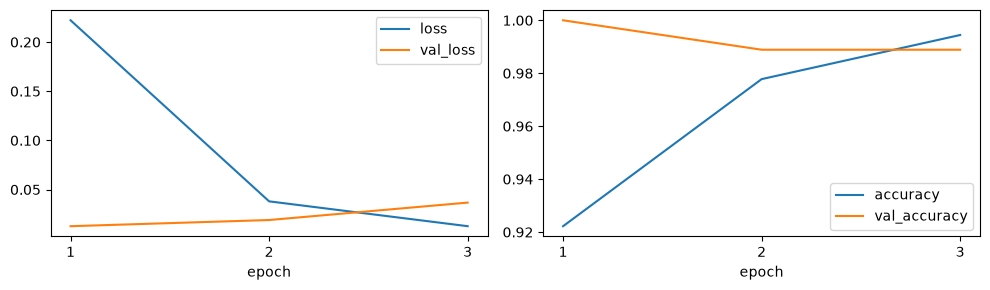

In [26]:
selected = checkpoint_writer.keep_best(2)
assert all(np.array_equal(old, weight.numpy()) for old, weight in zip(encoder_before, encoder.weights)), "encoder가 변경되었습니다. 학습 범위를 확인해주세요."
assert any(not np.array_equal(old, weight.numpy()) for old, weight in zip(adapter_before, task_model.get_layer("input_adapter").weights)), "adapter가 변경되지 않았습니다. gradient 경로를 확인해주세요."
print("encoder와 BN은 고정되고, adapter는 업데이트된 것을 확인했습니다.")

import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
epochs = np.arange(1, len(history.epoch) + 1)
for key in ["loss", "val_loss"]:
    axes[0].plot(epochs, history.history[key], label=key)
for key in ["accuracy", "val_accuracy"]:
    axes[1].plot(epochs, history.history[key], label=key)
for ax in axes:
    ax.set_xlabel("epoch")
    ax.set_xticks(epochs)
    ax.legend()
fig.tight_layout()
plt.show()


<a id="restore"></a>
# 4. Checkpoint 복원과 최종 평가

## Q10. 새 모델에 checkpoint 불러오기

복원은 학습 중 남아 있는 메모리에 의존하지 않아야 합니다.  
**커널을 재시작한 다음 처음 설정 셀, Q7의 `to_grayscale` 함수 정의 셀, Q8의 `build_task_model` 함수 정의 셀과 아래 셀들만** 실행해보세요.  
`RESTORE_RUN`은 앞에서 출력된 자신의 실행 폴더 이름으로 지정합니다.

`make_empty_encoder()`는 A/ImageNet 와 같은 구조만 만들고, 가중치를 읽지 않습니다.  
전체 checkpoint에 encoder 가중치까지 들어 있으므로 해당 checkpoint를 로딩하면 복원할 수 있습니다.

In [20]:
RESTORE_RUN = "run_002"  # 자신의 실행 폴더 이름으로 바꿔주세요.
restore_dir = RUNS / RESTORE_RUN
selected = read_checkpoints(restore_dir)
best = selected[0]
rgb_images, labels, splits, rows = read_species_data(TASK_DATA / "manifest.csv")
gray_images = to_grayscale(rgb_images)
index_by_id = {row["image_id"]: i for i, row in enumerate(rows)}
probe_indices = [index_by_id[image_id] for image_id in best["probe_ids"]]
print("선택한 checkpoint:", best["file"], "/ epoch", best["epoch"])

선택한 checkpoint: epoch_001.weights.h5 / epoch 1


In [21]:
# TODO 1: 기존과 동일한 모델 구조 생성
restored_model = build_task_model(make_empty_encoder())

# TODO 2: Checkpoint에서 가중치 불러오기
restored_model.load_weights(restore_dir / best["file"])

# 복원된 모델의 예측 결과 확인
restore_error = check_restored_predictions(
    restored_model,
    gray_images[probe_indices],
    best
)

복원 확인 통과 / 저장 시점과의 최대 차이: 0


가중치의 목적은 추론 복원입니다.  
해당 저장파일은 추론에 사용할 수 있지만, 학습 정보를 알 수는 없습니다.  
제공 코드는 저장 시점의 소수 입력에 대한 예측도 기록해둡니다.  
방금 계산한 예측을 그 기록과 비교하는 것이 위의 복원 확인입니다.

{'checkpoint': 'epoch_001.weights.h5', 'epoch': 1, 'test_count': 90, 'test_accuracy': 0.9777777777777777, 'test_loss': 0.06081952899694443, 'restore_max_abs_difference': 0.0}


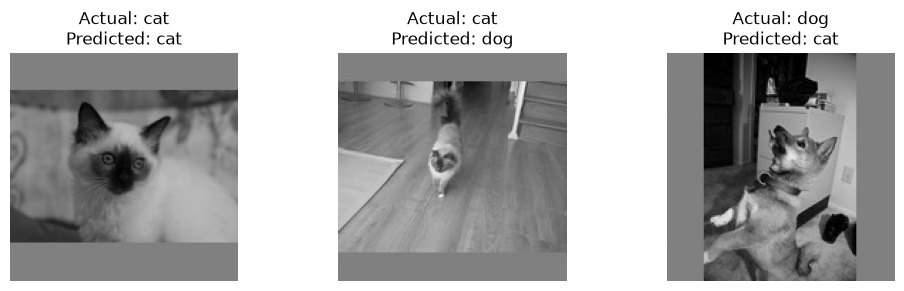

In [22]:
test = splits == "test"
test_logits = restored_model.predict(gray_images[test], batch_size=8, verbose=0)
test_accuracy = float(np.mean(test_logits.argmax(axis=1) == labels[test]))
test_loss = float(np.mean(keras.losses.sparse_categorical_crossentropy(
    labels[test], test_logits, from_logits=True).numpy()))
evaluation = {
    "checkpoint": best["file"], "epoch": best["epoch"],
    "test_count": int(test.sum()), "test_accuracy": test_accuracy,
    "test_loss": test_loss, "restore_max_abs_difference": restore_error,
}
write_json(restore_dir / "evaluation.json", evaluation)
print(evaluation)
show_predictions(gray_images[test], labels[test], test_logits)

## Q11. 새 Task의 흐름 정리하기

이 Task 는 기존의 Task 와 어떻게 다른가요?  
생각을 정리해보고, 이번 Task 를 처리해보면서 배운 점이나 느낀 점을 정리해봅시다.

**기존 Task는 RGB 이미지를 입력받아 개와 고양이의 6개 품종을 분류하는 문제였다. 반면 이번 Task는 흑백 이미지를 입력받아 고양이와 강아지라는 2개 범주로 분류하는 문제다.
이를 위해 기존 ResNet의 가중치는 유지하고, 흑백 1채널을 3채널로 변환하는 Input Adapter와 새로운 분류 Head를 추가했다. 특히 Adapter에서는 1×1 Convolution을 활용하여 기존 ResNet의 입력 형태에 맞게 채널을 확장했다.
학습 결과 기존 Encoder를 재학습하지 않고도 Test 정확도 97.78%를 달성했다. 이를 통해 사전학습된 모델의 특징 추출 능력이 새로운 입력 형식과 분류 문제에도 활용될 수 있음을 확인했다.**


<a id="wrap-up"></a>
# 마무리

다음 주에는 이미지의 격자 대신 길이가 달라지고 순서와 문맥이 중요한 데이터를 다룹니다.  
"이미지에서 공유한 특징과 달리, 순차 데이터에서는 무엇을 보존하고 전달해야 할까?"라는 질문을 가볍게 생각해봅시다.

**이미지 데이터는 픽셀의 공간적 관계가 중요하다. CNN은 주변 픽셀의 특징을 추출하고 이를 결합하여 이미지 전체를 이해한다.
반면 순차 데이터는 데이터의 순서와 앞뒤 문맥이 중요하다. 같은 단어나 정보라도 어떤 순서로 등장하고, 앞서 어떤 내용이 주어졌는지에 따라 의미가 달라질 수 있기 때문이다.따라서 이전 정보와의 관계, 순서, 문맥을 보존하고 전달하는 것이 중요할것이라고 생각한다.**


<a id="extra"></a>
# Extra - Representation Learning (필수 아님)

입력을 바로 정답으로 바꾸는 대신, 중간 특징으로 바꾼 뒤 문제에 맞는 출력을 만들 수 있습니다.  
입력 $x$를 중간 표현 $z$로 바꾼 뒤 출력 $y$를 만드는 관점입니다.  
유용한 표현은 이후 문제를 풀기 쉽게 만들며, 어떤 정보가 유용한지는 문제에 따라 달라집니다.

D는 GAP 벡터, E는 위치 배치가 남은 공간 특징에 새 head를 붙입니다.  
이 사례를 다시 보면, "어떤 표현을 재사용할 수 있을까?"와 "현재 표현에서 이미 잃은 정보는 무엇일까?"를 생각할 수 있습니다.

더 읽어보기:
- [MIT Vision Book 30장, 30.1~30.3](https://visionbook.mit.edu/representation_learning.html)
- [37장 Heads and Probes](https://visionbook.mit.edu/transfer_learning.html#heads-and-probes)

**BN 이동 통계가 궁금하다면**: 학습에서는 현재 batch 통계를, 추론에서는 학습 중 누적한 통계를
사용하는 이유를 [Keras BN 문서](https://keras.io/api/layers/normalization_layers/batch_normalization/)에서
확인해볼 수 있습니다.  
이 내용을 바탕으로 keras 의 Batch Normalization 의 파라미터가 무엇인지 파악해봅시다.